In [2]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer


#carpetas locales para los datos y las figuras
DATA_DIR = '../data'
FIG_DIR = '../figuras/eda'
os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(FIG_DIR, exist_ok=True)

#funcion para guardar figuras en png en carpeta local
def guardar_figura(nombre):
    plt.savefig(f'{FIG_DIR}/{nombre}.png', bbox_inches='tight', dpi=150)

RANDOM_STATE = 42

#estilo y colores de las graficas
sns.set_theme(style='whitegrid', palette='Set2')
SET2 = sns.color_palette('Set2')

PALETTE = {
    'No': SET2[0],
    'Yes': SET2[1]
}

In [3]:
df = pd.read_csv(f'{DATA_DIR}/ecommerce_sales_34500.csv') #leemos csv descargado con el dataset
print(f'Dimensiones del dataset: {df.shape[0]} filas x {df.shape[1]} columnas') #sacamos dimensiones del dataset
df.head()

Dimensiones del dataset: 34500 filas x 17 columnas


,order_id,customer_id,product_id,category,price,discount,quantity,payment_method,order_date,delivery_time_days,region,returned,total_amount,shipping_cost,profit_margin,customer_age,customer_gender
0,O100000,C17270,P234890,Home,164.08,0.15,1,Credit Card,2023-12-23,4,West,No,139.47,7.88,31.17,60,Female
1,O100001,C17603,P228204,Grocery,24.73,0.00,1,Credit Card,2025-04-03,6,South,No,24.73,4.60,-2.62,37,Male
2,O100002,C10860,P213892,Electronics,175.58,0.05,1,Credit Card,2024-10-08,4,North,No,166.80,6.58,13.44,34,Male
3,O100003,C15390,P208689,Electronics,63.67,0.00,1,UPI,2024-09-14,6,South,No,63.67,5.50,2.14,21,Female
4,O100004,C15226,P228063,Home,16.33,0.15,1,COD,2024-12-21,6,East,No,13.88,2.74,1.15,39,Male


In [4]:
df.info() #vemos informacion sobre nulos y tipos de datos de las variables caracteristicas

<class 'pandas.DataFrame'>
RangeIndex: 34500 entries, 0 to 34499
Data columns (total 17 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   order_id            34500 non-null  str    
 1   customer_id         34500 non-null  str    
 2   product_id          34500 non-null  str    
 3   category            34500 non-null  str    
 4   price               34500 non-null  float64
 5   discount            34500 non-null  float64
 6   quantity            34500 non-null  int64  
 7   payment_method      34500 non-null  str    
 8   order_date          34500 non-null  str    
 9   delivery_time_days  34500 non-null  int64  
 10  region              34500 non-null  str    
 11  returned            34500 non-null  str    
 12  total_amount        34500 non-null  float64
 13  shipping_cost       34500 non-null  float64
 14  profit_margin       34500 non-null  float64
 15  customer_age        34500 non-null  int64  
 16  customer_gender

In [5]:
#sacamos nulos por columna
nulos = df.isnull().sum()
print('Valores ausentes por columna:')
print(nulos)
print(f'\nTotal de valores ausentes en el dataset: {nulos.sum()}')

Valores ausentes por columna:
order_id              0
customer_id           0
product_id            0
category              0
price                 0
discount              0
quantity              0
payment_method        0
order_date            0
delivery_time_days    0
region                0
returned              0
total_amount          0
shipping_cost         0
profit_margin         0
customer_age          0
customer_gender       0
dtype: int64

Total de valores ausentes en el dataset: 0


In [6]:
#vemos filas duplicadas, order_id duplicados y frecuencia de pedidos por cliente y frecuencia de productos aparecidos en cada pedido
print(f'Filas totalmente duplicadas: {df.duplicated().sum()}')
print(f'order_id duplicados: {df["order_id"].duplicated().sum()}')
print(f'customer_id únicos: {df["customer_id"].nunique()} sobre {len(df)} pedidos '
      f'({df.shape[0]/df["customer_id"].nunique():.1f} pedidos/cliente de media)')
print(f'product_id únicos: {df["product_id"].nunique()} sobre {len(df)} pedidos')

Filas totalmente duplicadas: 0
order_id duplicados: 0
customer_id únicos: 7903 sobre 34500 pedidos (4.4 pedidos/cliente de media)
product_id únicos: 24912 sobre 34500 pedidos


In [7]:
num_cols = ['price', 'discount', 'quantity', 'delivery_time_days',
            'total_amount', 'shipping_cost', 'profit_margin', 'customer_age']
cat_cols = ['category', 'payment_method', 'region', 'customer_gender', 'returned']

desc_num = df[num_cols].describe().T
desc_num

,count,mean,std,min,25%,50%,75%,max
price,34500.0,119.391632,195.620477,1.01,16.69,45.66,130.9500,2930.47
discount,34500.0,0.049291,0.069894,0.00,0.00,0.00,0.1000,0.30
quantity,34500.0,1.490725,0.932270,1.00,1.00,1.00,2.0000,5.00
delivery_time_days,34500.0,4.814203,1.242141,3.00,4.00,5.00,6.0000,13.00
total_amount,34500.0,170.008494,357.503014,0.82,19.71,56.82,168.5300,12931.80
shipping_cost,34500.0,6.152120,2.389539,0.00,4.42,6.09,7.8300,15.65
profit_margin,34500.0,28.116505,53.352947,-6.20,1.50,10.55,33.1325,1536.17
customer_age,34500.0,43.474377,14.980682,18.00,31.00,43.00,56.0000,69.00


In [8]:
#sacamos frecuencia y porcentaje de las variables categoricas
for c in cat_cols:
    print(f'--- {c} ---')
    print(df[c].value_counts())
    print((df[c].value_counts(normalize=True) * 100).round(2))
    print()

--- category ---
category
Fashion        6254
Electronics    6180
Home           5487
Toys           4247
Sports         4171
Beauty         4103
Grocery        4058
Name: count, dtype: int64
category
Fashion        18.13
Electronics    17.91
Home           15.90
Toys           12.31
Sports         12.09
Beauty         11.89
Grocery        11.76
Name: proportion, dtype: float64

--- payment_method ---
payment_method
Credit Card    12170
Debit Card      8505
COD             4160
UPI             4156
PayPal          3444
Wallet          2065
Name: count, dtype: int64
payment_method
Credit Card    35.28
Debit Card     24.65
COD            12.06
UPI            12.05
PayPal          9.98
Wallet          5.99
Name: proportion, dtype: float64

--- region ---
region
South      7584
North      7572
East       6904
West       6808
Central    5632
Name: count, dtype: int64
region
South      21.98
North      21.95
East       20.01
West       19.73
Central    16.32
Name: proportion, dtype: float64


returned
No     32597
Yes     1903
Name: count, dtype: int64
returned
No     94.48
Yes     5.52
Name: proportion, dtype: float64


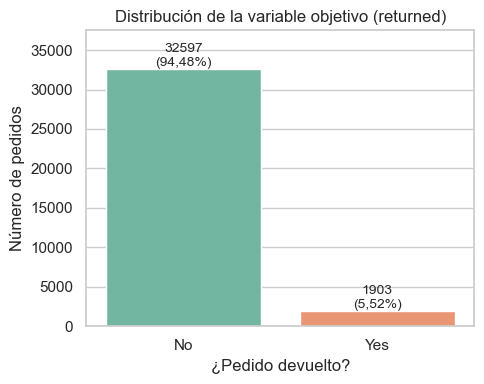

In [9]:
target_counts = df['returned'].value_counts() #numero de No y Yes de variable returned
target_pct = df['returned'].value_counts(normalize=True) * 100 #porcentaje de devuelto/no devuelto
print(target_counts) 
print(target_pct.round(2))

#dibujamos distribucion de la variable objetivo
fig, ax = plt.subplots(figsize=(5, 4))
sns.countplot(data=df, x='returned', order=['No', 'Yes'], hue='returned', palette=PALETTE, legend=False, ax=ax) #creamos grafico de barras con seaborn
for i, clase in enumerate(['No', 'Yes']): 
    pct = f'{target_pct[clase]:.2f}'.replace('.', ',') #porcentaje con coma decimal
    ax.text(i, target_counts[clase] + 400, f'{target_counts[clase]}\n({pct}%)', #colocacion de texto encima de las barras
            ha='center', fontsize=10)
ax.set_ylim(0, target_counts.max() * 1.15) #margen para que el texto no se pise con el titulo
ax.set_xlabel('¿Pedido devuelto?')
ax.set_ylabel('Número de pedidos')
ax.set_title('Distribución de la variable objetivo (returned)')
plt.tight_layout()
guardar_figura('eda_balance_clases')
plt.show()

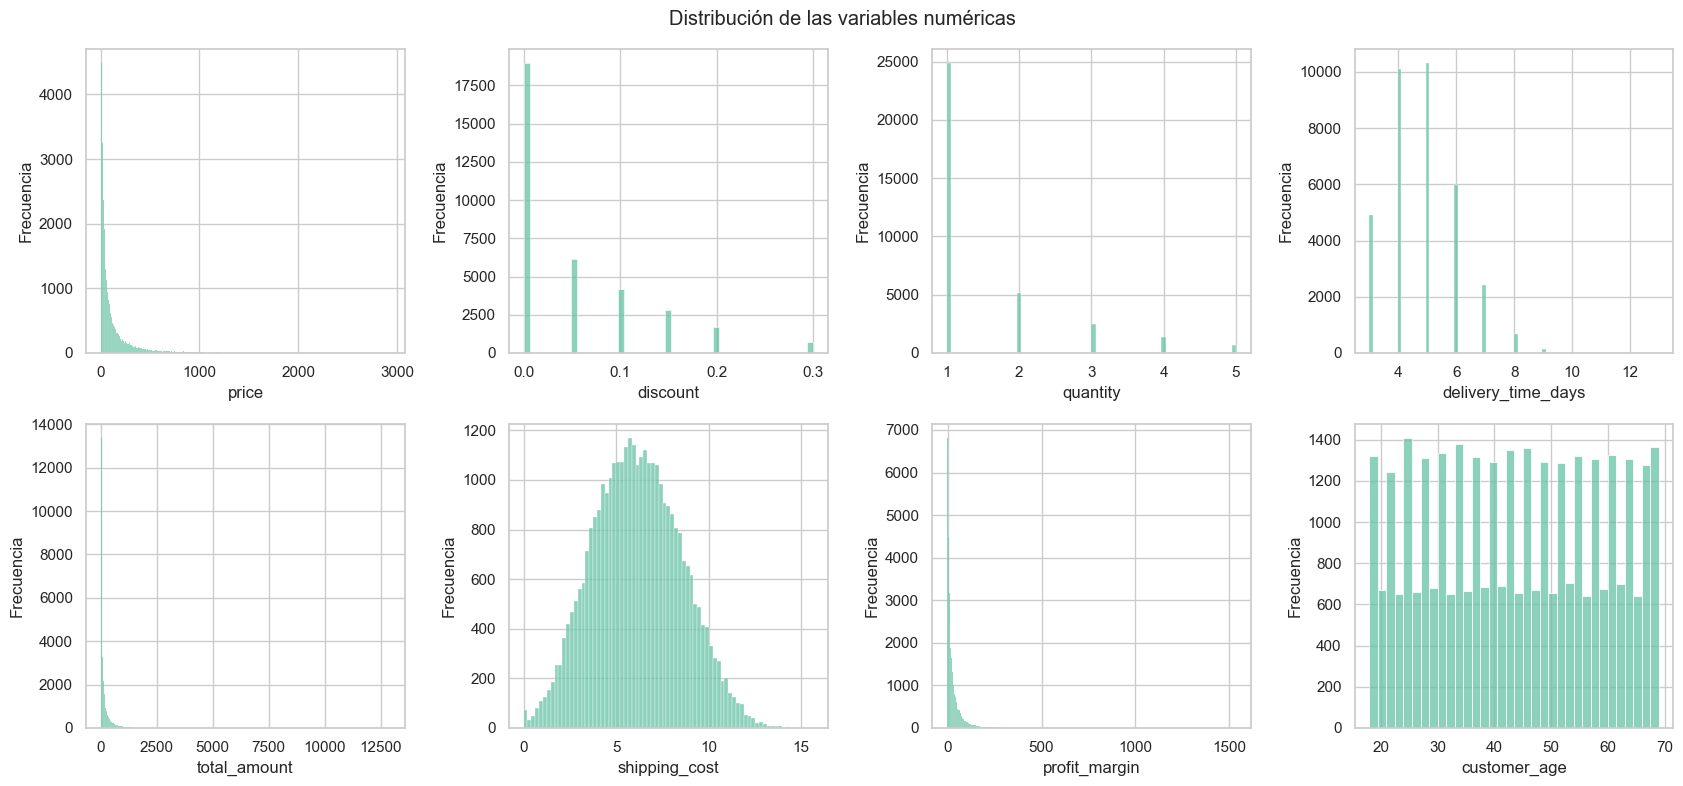

In [10]:
fig, axes = plt.subplots(2, 4, figsize=(17, 8))
for ax, col in zip(axes.flatten(), num_cols): #recorremos las variables numericas para dibujar su histograma
    sns.histplot(df[col], ax=ax, color=SET2[0]) #histograma de la distribucion
    ax.set_xlabel(col)
    ax.set_ylabel('Frecuencia')
fig.suptitle('Distribución de las variables numéricas')
plt.tight_layout()
guardar_figura('eda_histogramas_numericas')
plt.show()

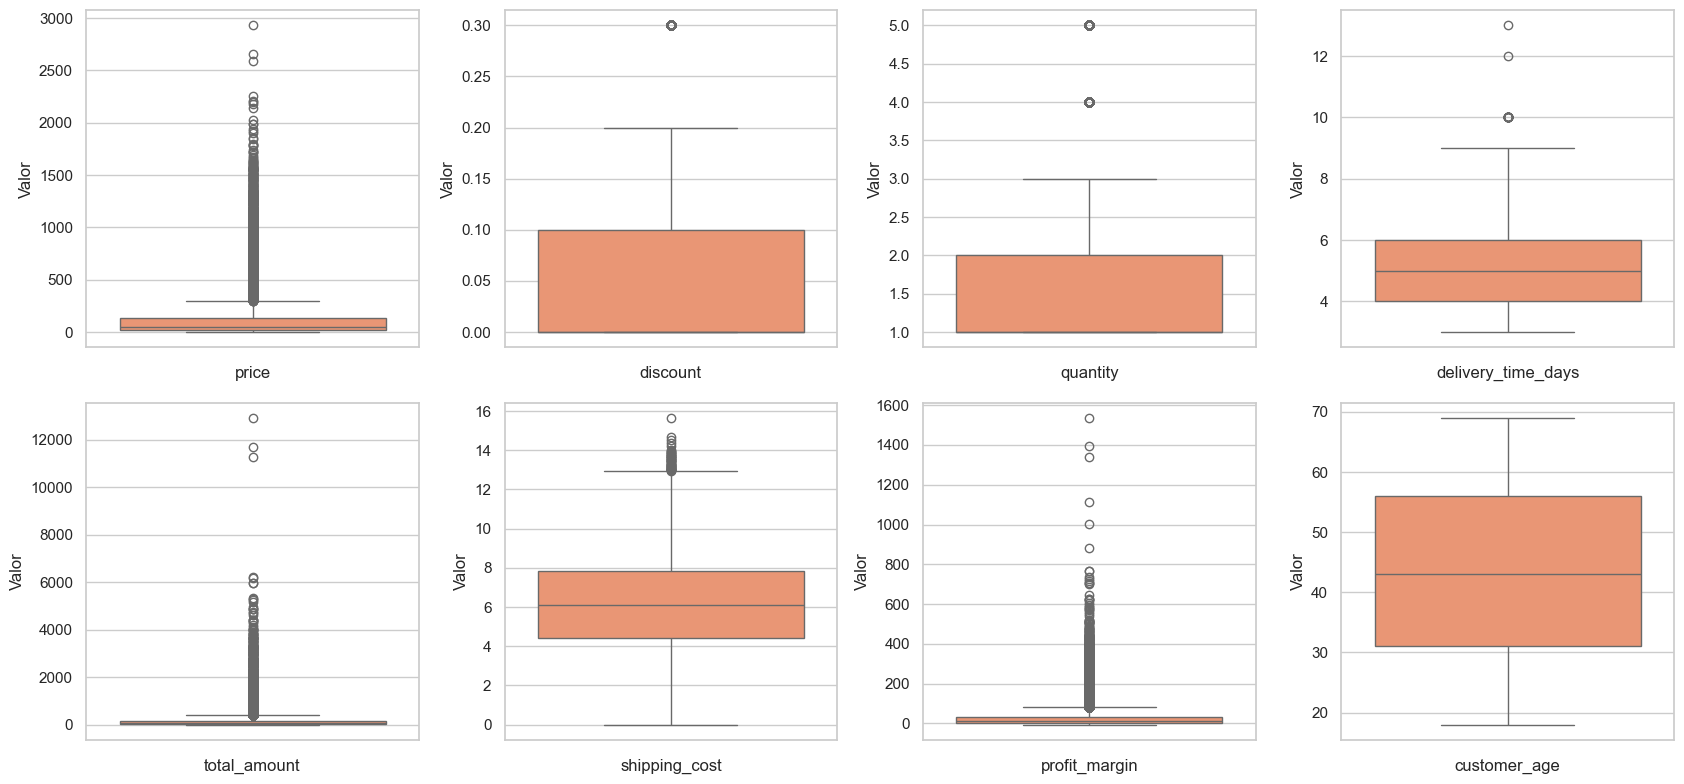

In [11]:
#lo mismo de antes pero dibujamos los boxplots de las variables numericas
fig, axes = plt.subplots(2, 4, figsize=(17, 8))
for ax, col in zip(axes.flatten(), num_cols):
    sns.boxplot(y=df[col], ax=ax, color=SET2[1])
    ax.set_xlabel(col)
    ax.set_ylabel('Valor')
plt.tight_layout()
guardar_figura('eda_boxplots_numericas')
plt.show()

In [12]:
#sacamos coeficiente de asimetria de las variables numericas
print('Coeficiente de asimetría (skewness):')
print(df[num_cols].skew().round(2).sort_values(ascending=False))

Coeficiente de asimetría (skewness):
total_amount          8.22
profit_margin         6.04
price                 3.70
quantity              2.05
discount              1.54
delivery_time_days    0.56
shipping_cost         0.12
customer_age          0.01
dtype: float64


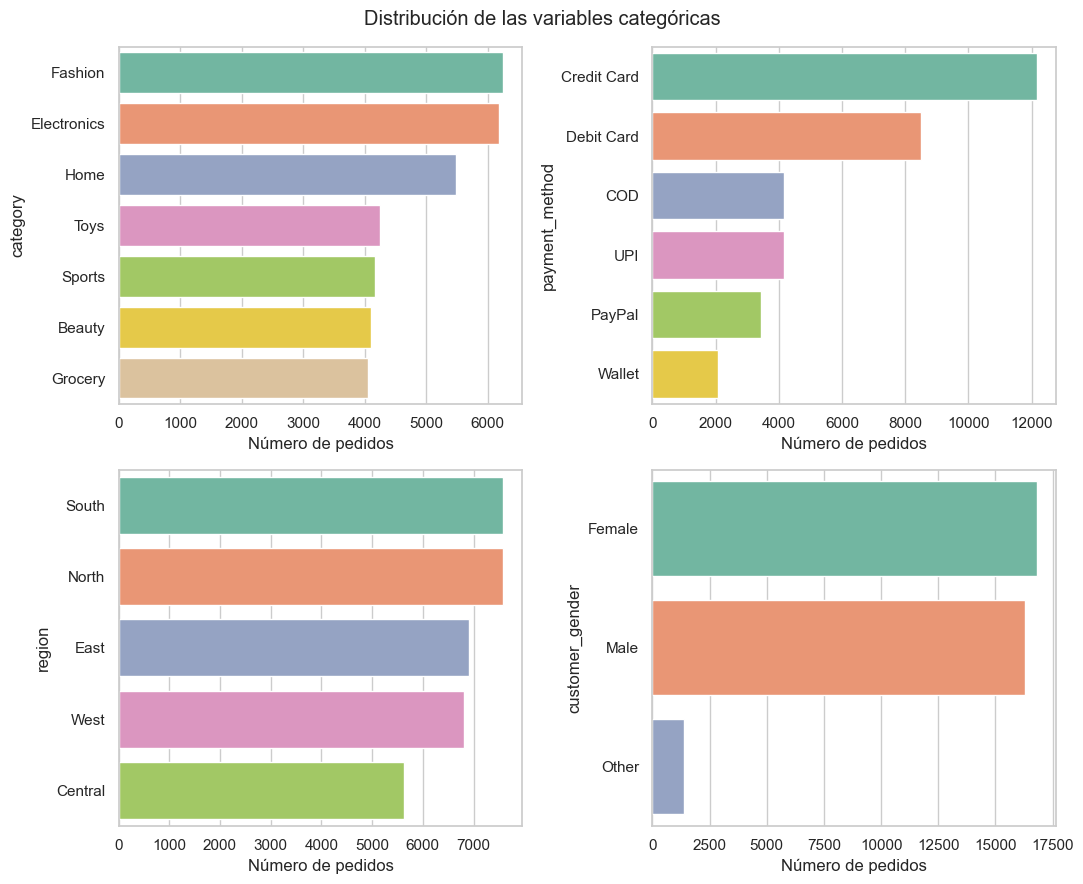

In [13]:
cat_features = ['category', 'payment_method', 'region', 'customer_gender'] #variables categoricas
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for ax, col in zip(axes.flatten(), cat_features): #recorremos las variables categoricas para dibujar su distribucion
    order = df[col].value_counts().index
    sns.countplot(data=df, y=col, order=order, hue=col, hue_order=order, palette='Set2', legend=False, ax=ax) #grafico de barras horizontales
    ax.set_xlabel('Número de pedidos')
fig.suptitle('Distribución de las variables categóricas')
plt.tight_layout()
guardar_figura('eda_barras_categoricas')
plt.show()

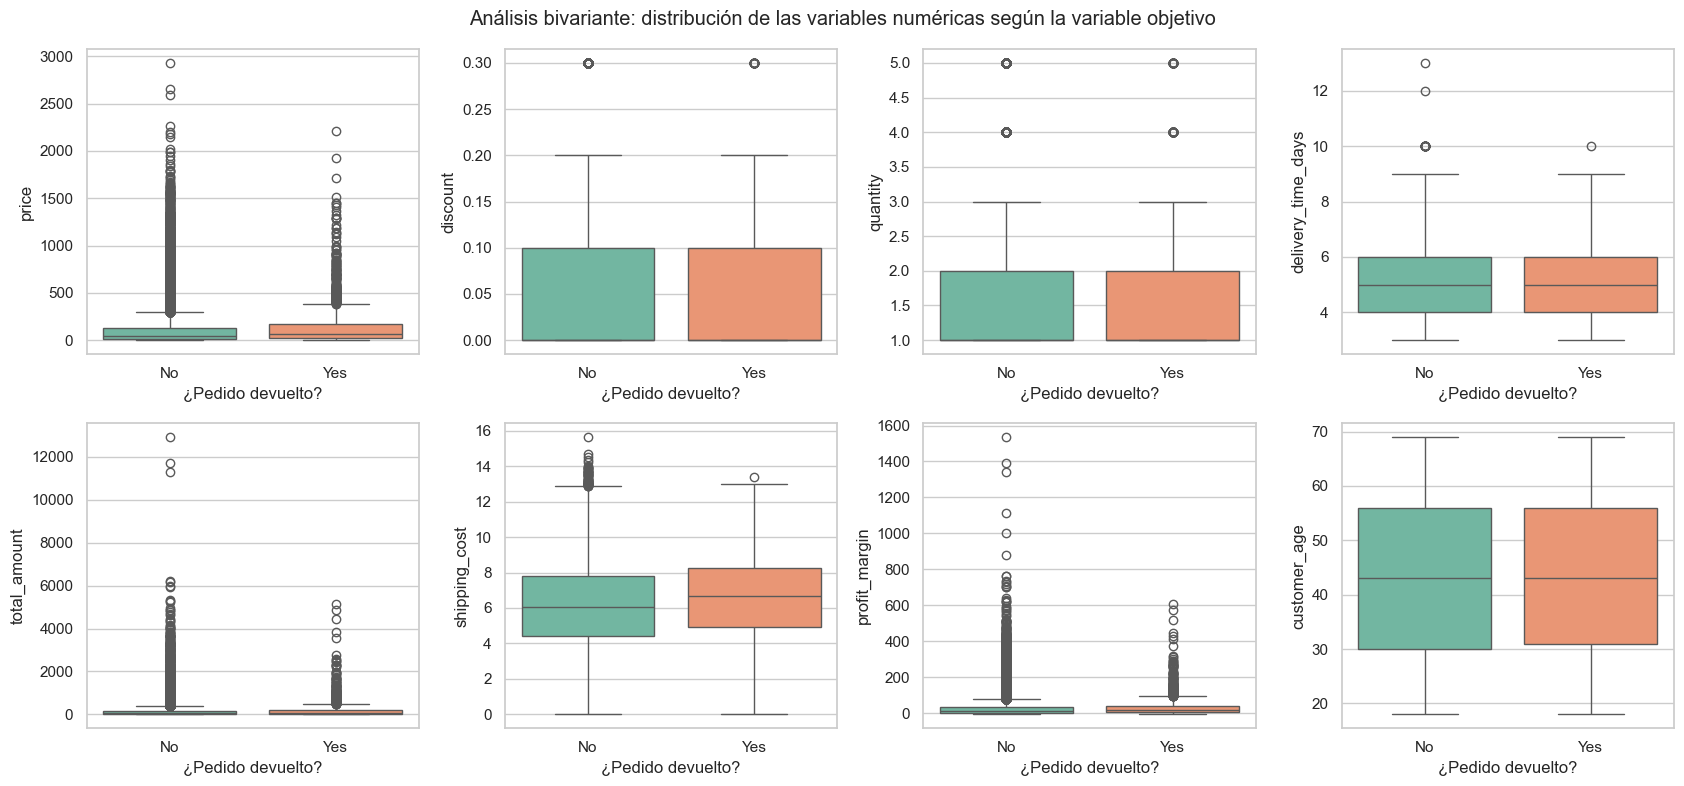

In [14]:
fig, axes = plt.subplots(2, 4, figsize=(17, 8))
for ax, col in zip(axes.flatten(), num_cols):
    sns.boxplot(data=df, x='returned', y=col, order=['No', 'Yes'], hue='returned', palette=PALETTE, legend=False, ax=ax) #boxplot con returned en eje x para sacar la distribucion bivariante de las numericas
    ax.set_xlabel('¿Pedido devuelto?')
    ax.set_ylabel(col)
fig.suptitle('Análisis bivariante: distribución de las variables numéricas según la variable objetivo')
plt.tight_layout()
guardar_figura('eda_boxplots_vs_target')
plt.show()

In [15]:
df['returned_bin'] = (df['returned'] == 'Yes').astype(int) #columna con 1 si el pedido es devuelto, 0 si no
corr_target = df[num_cols + ['returned_bin']].corr()['returned_bin'].drop('returned_bin')
corr_target.sort_values(key=abs, ascending=False)

shipping_cost         0.048624
price                 0.031785
total_amount          0.023167
profit_margin         0.019752
delivery_time_days    0.004556
discount             -0.003091
customer_age         -0.000922
quantity              0.000702
Name: returned_bin, dtype: float64

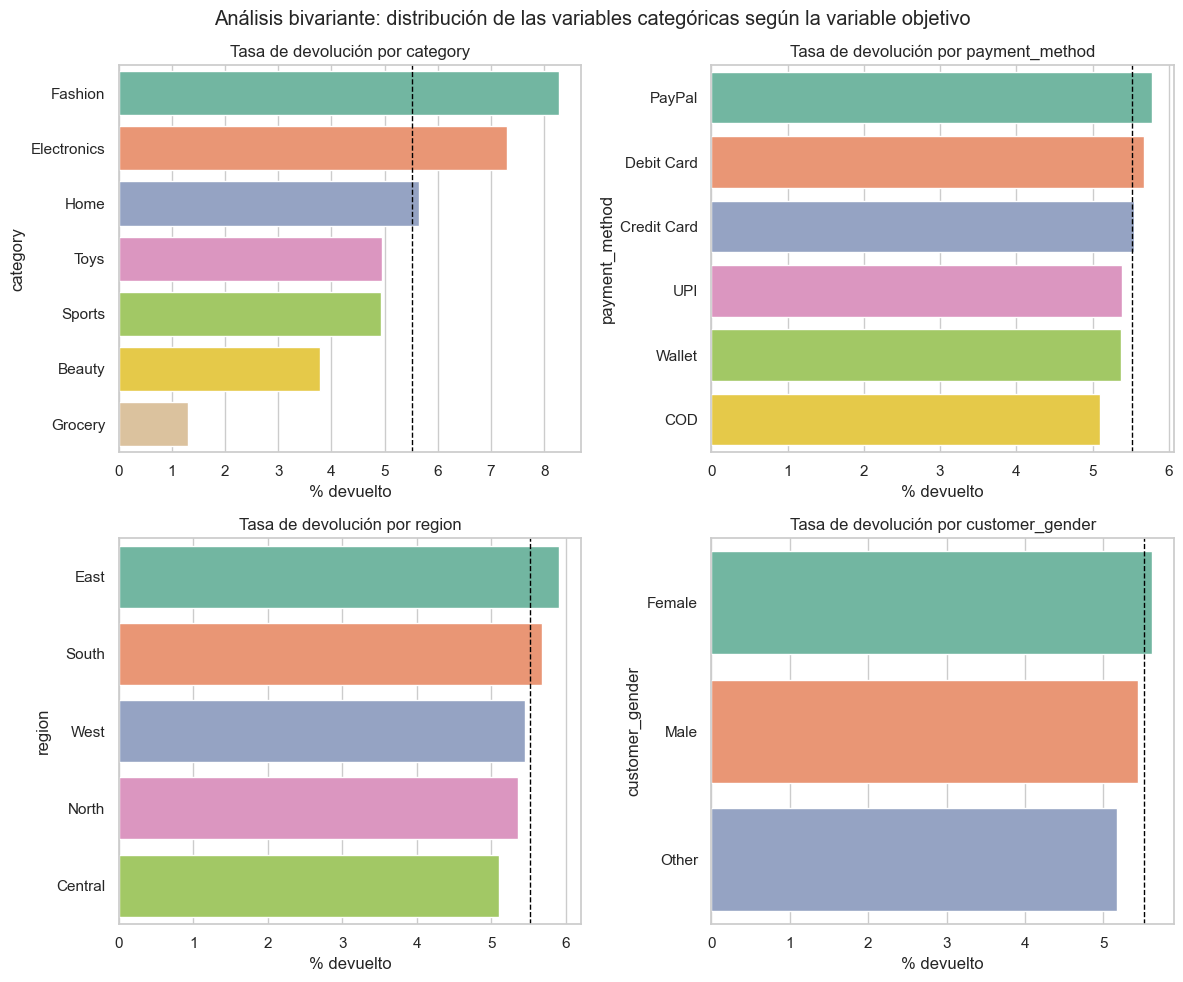

In [16]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
tasa_global = df['returned_bin'].mean() * 100
for ax, col in zip(axes.flatten(), cat_features):
    tasa = df.groupby(col)['returned_bin'].mean().sort_values(ascending=False) * 100 #porcentajes de pedidos devueltos
    sns.barplot(x=tasa.values, y=tasa.index, hue=tasa.index, palette='Set2', legend=False, ax=ax) #dibujamos distribucion de pedidos devueltos en funcion del valor de la variable categorica
    ax.set_title(f'Tasa de devolución por {col}')
    ax.set_xlabel('% devuelto')
    ax.set_ylabel(col)
    ax.axvline(tasa_global, color='black', linestyle='--', linewidth=1)
fig.suptitle('Análisis bivariante: distribución de las variables categóricas según la variable objetivo')
plt.tight_layout()
guardar_figura('eda_tasa_devolucion_categoricas')
plt.show()

In [17]:
print(f'Tasa de devolución global: {tasa_global:.2f}%\n')
for col in cat_features:
    print(f'--- {col} ---')
    print((df.groupby(col)['returned_bin'].mean() * 100).round(2).sort_values(ascending=False)) #imprimimos para verlo bien el porcentaje de pedidos devueltos por categoria y valor de la variable categorica
    print()

Tasa de devolución global: 5.52%

--- category ---
category
Fashion        8.28
Electronics    7.30
Home           5.65
Toys           4.94
Sports         4.94
Beauty         3.78
Grocery        1.31
Name: returned_bin, dtype: float64

--- payment_method ---
payment_method
PayPal         5.78
Debit Card     5.67
Credit Card    5.55
UPI            5.39
Wallet         5.38
COD            5.10
Name: returned_bin, dtype: float64

--- region ---
region
East       5.91
South      5.68
West       5.45
North      5.36
Central    5.10
Name: returned_bin, dtype: float64

--- customer_gender ---
customer_gender
Female    5.62
Male      5.44
Other     5.17
Name: returned_bin, dtype: float64



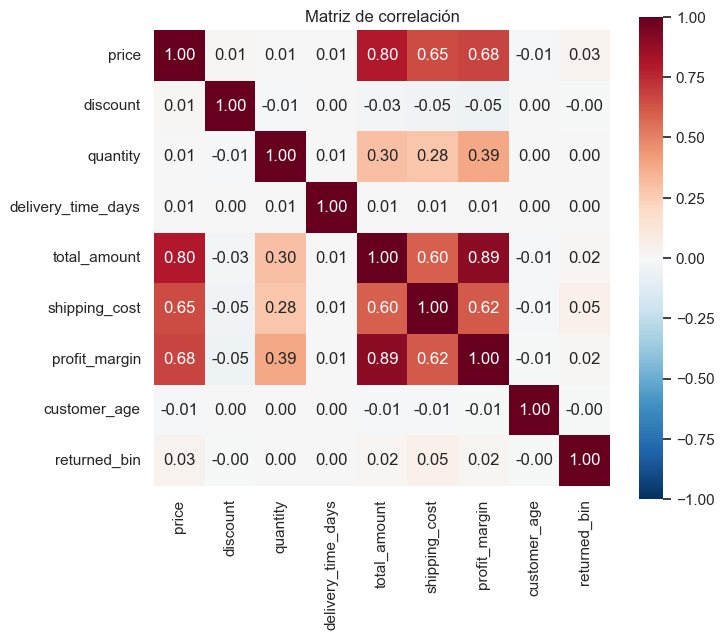

In [18]:
fig, ax = plt.subplots(figsize=(7.5, 6.5))
matriz_corr = df[num_cols + ['returned_bin']].corr()
sns.heatmap(matriz_corr, annot=True, fmt='.2f', cmap='RdBu_r', center=0,
            vmin=-1, vmax=1, square=True, ax=ax) #hacemos heatmap de las correlaciones para obtener la matriz de correlacion
ax.set_title('Matriz de correlación')
plt.tight_layout()
guardar_figura('eda_matriz_correlacion')
plt.show()

In [19]:
#deteccion de outliers
def contar_outliers_iqr(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1 #rango intercuartilico
    lim_inf, lim_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr #limites superior e inferior 
    return ((serie < lim_inf) | (serie > lim_sup)).sum() #contamos todo lo que queda por abajo y todo lo que queda por encima (outliers)

outliers = {col: contar_outliers_iqr(df[col]) for col in num_cols} 
tabla_outliers = pd.DataFrame({
    'n_outliers': outliers,
    '% del total': {k: round(v / len(df) * 100, 2) for k, v in outliers.items()} #porcentaje de outliers sobre todos los registros
})
tabla_outliers.sort_values('% del total', ascending=False) #ordenamos de mayor a menor

,n_outliers,% del total
total_amount,3792,10.99
price,3632,10.53
profit_margin,3025,8.77
quantity,2070,6.00
discount,704,2.04
shipping_cost,48,0.14
delivery_time_days,27,0.08
customer_age,0,0.00


In [20]:
#sacamos mes y dia de la semana de order_date para ver si hay algun patron estacional en las devoluciones
fechas = pd.to_datetime(df['order_date'])
print(f'Rango de fechas: {fechas.min().date()} a {fechas.max().date()}\n')
df['mes'] = fechas.dt.month
df['dia_semana'] = fechas.dt.dayofweek #0 = lunes, 6 = domingo

for col in ['mes', 'dia_semana']:
    tasa = (df.groupby(col)['returned_bin'].mean() * 100).round(2) #porcentaje de pedidos devueltos por mes y por dia
    _, p_valor, _, _ = chi2_contingency(pd.crosstab(df[col], df['returned_bin'])) #test chi-cuadrado de independencia con la variable objetivo
    print(f'--- {col} ---')
    print(tasa.to_string())
    print(f'Rango de la tasa: {tasa.min():.2f}% - {tasa.max():.2f}% | p-valor chi-cuadrado: {p_valor:.3f}\n')

Rango de fechas: 2023-09-12 a 2025-09-11

--- mes ---
mes
1     4.95
2     5.49
3     5.51
4     6.03
5     5.58
6     5.34
7     5.75
8     5.39
9     5.72
10    5.15
11    5.42
12    5.83
Rango de la tasa: 4.95% - 6.03% | p-valor chi-cuadrado: 0.910

--- dia_semana ---
dia_semana
0    5.93
1    5.51
2    5.55
3    5.91
4    5.59
5    5.12
6    4.98
Rango de la tasa: 4.98% - 5.93% | p-valor chi-cuadrado: 0.286



In [21]:
df_model = df.drop(columns=['order_id', 'customer_id', 'product_id', 'order_date',
                              'returned_bin', 'mes', 'dia_semana']) #eliminamos variables no informativas y que no aportan señal

X = df_model.drop(columns=['returned']) #Matriz de datos de la variable caracteristica
y = (df_model['returned'] == 'Yes').astype(int) #variable objetivo

print('Variables predictoras:', list(X.columns))
print('Distribución de la clase objetivo:')
print(y.value_counts(normalize=True).round(4))

Variables predictoras: ['category', 'price', 'discount', 'quantity', 'payment_method', 'delivery_time_days', 'region', 'total_amount', 'shipping_cost', 'profit_margin', 'customer_age', 'customer_gender']
Distribución de la clase objetivo:
returned
0    0.9448
1    0.0552
Name: proportion, dtype: float64


In [22]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
) #split estratificado de 80% entrenamiento 20% test
print(f'Train: {X_train.shape[0]} filas | Test: {X_test.shape[0]} filas')
print('Balance en train:', y_train.value_counts(normalize=True).round(4).to_dict())
print('Balance en test: ', y_test.value_counts(normalize=True).round(4).to_dict())

Train: 27600 filas | Test: 6900 filas
Balance en train: {0: 0.9449, 1: 0.0551}
Balance en test:  {0: 0.9448, 1: 0.0552}


In [23]:
num_features = ['price', 'discount', 'quantity', 'delivery_time_days',
                 'total_amount', 'shipping_cost', 'profit_margin', 'customer_age']
cat_features = ['category', 'payment_method', 'region', 'customer_gender']

preprocesador = ColumnTransformer(transformers=[
    ('num', StandardScaler(), num_features),
    ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), cat_features)
]) #creamos nuestro objeto preprocesador que aplica Standard Scaler sobre las variables caracteristicas numericas y OneHotEncoder sobre variables caracteristicas categoricas

#aplicamos preprocesamiento sobre datos de entrenamiento y test con lo aprendido del conjunto de entrenamiento, para evitar data leakage
X_train_proc = preprocesador.fit_transform(X_train) 
X_test_proc = preprocesador.transform(X_test)

nombres_ohe = preprocesador.named_transformers_['cat'].get_feature_names_out(cat_features) #sacamos los nombres de las nuevas variables creadas por el OneHotEncoding
nombres_finales = num_features + list(nombres_ohe) #nombre de todas las nuevas columnas (variables caracteristicas)

#construimos el dataset de variables de entrenamiento y test con las denominaciones de las columnas
X_train_proc = pd.DataFrame(X_train_proc, columns=nombres_finales, index=X_train.index) 
X_test_proc = pd.DataFrame(X_test_proc, columns=nombres_finales, index=X_test.index)

print(f'Forma final de X_train: {X_train_proc.shape}')
X_train_proc.head()

Forma final de X_train: (27600, 25)


,price,discount,quantity,delivery_time_days,total_amount,shipping_cost,profit_margin,customer_age,category_Electronics,category_Fashion,...,payment_method_Debit Card,payment_method_PayPal,payment_method_UPI,payment_method_Wallet,region_East,region_North,region_South,region_West,customer_gender_Male,customer_gender_Other
2221,1.124893,-0.704539,2.690835,-0.656701,3.316171,1.791483,6.404234,-0.964011,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
18551,-0.583826,0.725313,-0.527114,0.952831,-0.461063,-1.250735,-0.579503,-0.496924,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
15445,-0.597756,0.010387,0.545536,1.757597,-0.461480,-1.045123,-0.562532,0.503978,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
20114,-0.381484,-0.704539,3.763484,0.952831,0.149128,0.310238,0.598937,0.237071,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3524,0.875169,-0.704539,0.545536,0.148065,1.148412,1.388652,0.603600,-0.897284,1.0,0.0,...,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0


In [24]:
#guardamos datasets de X_train, X_test, y_train y y_test a csv en carpeta local
X_train_proc.to_csv(f'{DATA_DIR}/X_train_proc.csv', index=False)
X_test_proc.to_csv(f'{DATA_DIR}/X_test_proc.csv', index=False)
y_train.to_csv(f'{DATA_DIR}/y_train.csv', index=False)
y_test.to_csv(f'{DATA_DIR}/y_test.csv', index=False)

print(f'Ficheros guardados en ./{DATA_DIR}/:')
print('  X_train_proc.csv, X_test_proc.csv, y_train.csv, y_test.csv')

Ficheros guardados en ./data/:
  X_train_proc.csv, X_test_proc.csv, y_train.csv, y_test.csv
